<a href="https://colab.research.google.com/github/stevenpanchi41/IA-Practicas/blob/main/Practica_02_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

UNIVERSIDAD POLITECNICA SALESIANA

PRACTICA02

NOMBRE:STEVEN ROLANDO PANCHI HERRERA

FECHA:20/10/2026


In [3]:

# FASE 1: ANATOMIA DE UN DATASET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
    RobustScaler
)

from sklearn.model_selection import train_test_split

print( "Todas las librerías cargadas correctamente")

# Crear el dataset de estudiantes
datos = {
    "nombre": ["Ana", "Luis", "María", "Carlos", "Sofía", "Diego"],
    "edad": [21, 23, 20, 25, 22, 21],
    "promedio_gpa": [8.9, 7.4, 9.5, 6.1, 8.2, 7.8],
    "horas_estudio": [18, 10, 22, 6, 15, 12],
    "distancia_km": [2.5, 15.0, 0.8, 40.2, 5.1, 8.7],
    "carrera": [
        "Computación", "Computación", "Redes",
        "Redes", "Computación", "Redes"
    ],
    "nivel_ingles": [
        "Básico", "Intermedio", "Avanzado",
        "Básico", "Avanzado", "Intermedio"
    ],
    "beca": [1, 0, 1, 0, 1, 0],
    "aprobado": ["Sí", "No", "Sí", "No", "Sí", "No"]
}

df = pd.DataFrame(datos)

print("\n=== DATASET DE ESTUDIANTES ===")
print(df.to_string(index=False))

print("\nDimensiones del dataset:", df.shape)
print("\n=== TIPOS DE DATOS ===")
print(df.dtypes)

print("\n=== ESTADÍSTICAS DESCRIPTIVAS ===")
print(df.describe())


Todas las librerías cargadas correctamente

=== DATASET DE ESTUDIANTES ===
nombre  edad  promedio_gpa  horas_estudio  distancia_km     carrera nivel_ingles  beca aprobado
   Ana    21           8.9             18           2.5 Computación       Básico     1       Sí
  Luis    23           7.4             10          15.0 Computación   Intermedio     0       No
 María    20           9.5             22           0.8       Redes     Avanzado     1       Sí
Carlos    25           6.1              6          40.2       Redes       Básico     0       No
 Sofía    22           8.2             15           5.1 Computación     Avanzado     1       Sí
 Diego    21           7.8             12           8.7       Redes   Intermedio     0       No

Dimensiones del dataset: (6, 9)

=== TIPOS DE DATOS ===
nombre            object
edad               int64
promedio_gpa     float64
horas_estudio      int64
distancia_km     float64
carrera           object
nivel_ingles      object
beca               in

Actividad 1.1: Identifica la estructura

P1. ¿Cuántas instancias tiene el dataset y qué representa cada una?

El dataset tiene 6 instancias (filas). Cada instancia representa a un estudiante con información sobre su edad, promedio académico, horas de estudio, distancia al centro educativo, carrera, nivel de inglés, beca y estado de aprobación.

P2. ¿Cuáles son los atributos, las features y el label?

Los atributos son: nombre, edad, promedio_gpa, horas_estudio, distancia_km, carrera, nivel_ingles, beca y aprobado.

Si el objetivo es predecir si un estudiante aprueba, el label es `aprobado`. Las posibles features son edad, promedio_gpa, horas_estudio, distancia_km, carrera, nivel_ingles y beca. La columna nombre se excluye porque es un identificador y no aporta información predictiva útil.

P3. ¿Nombre debería ser una feature?

No. El nombre identifica al estudiante, pero no explica su rendimiento académico. Utilizarlo podría introducir información irrelevante y hacer que el modelo aprenda patrones sin significado generalizable.

In [4]:

# ============================================
# ACTIVIDAD 1.2: CLASIFICACION DE VARIABLES
# ============================================

clasificacion = {
    "columna": [
        "edad", "promedio_gpa", "horas_estudio",
        "distancia_km", "carrera", "nivel_ingles",
        "beca", "aprobado"
    ],
    "cuantitativa_o_cualitativa": [
        "Cuantitativa", "Cuantitativa", "Cuantitativa",
        "Cuantitativa", "Cualitativa", "Cualitativa",
        "Cualitativa", "Cualitativa"
    ],
    "discreta_o_continua": [
        "Discreta", "Continua", "Discreta", "Continua",
        "No aplica", "No aplica", "No aplica", "No aplica"
    ],
    "nominal_u_ordinal": [
        "NA", "NA", "NA", "NA",
        "Nominal", "Ordinal", "Nominal", "Nominal"
    ]
}

df_tipos = pd.DataFrame(clasificacion)

print("=== CLASIFICACION DE VARIABLES ===")
print(df_tipos.to_string(index=False))

print("\n=== TIPOS DETECTADOS POR PANDAS ===")
print(df.dtypes)

print("\n=== ESTADISTICAS NUMERICAS ===")
print(df.describe())


=== CLASIFICACION DE VARIABLES ===
      columna cuantitativa_o_cualitativa discreta_o_continua nominal_u_ordinal
         edad               Cuantitativa            Discreta                NA
 promedio_gpa               Cuantitativa            Continua                NA
horas_estudio               Cuantitativa            Discreta                NA
 distancia_km               Cuantitativa            Continua                NA
      carrera                Cualitativa           No aplica           Nominal
 nivel_ingles                Cualitativa           No aplica           Ordinal
         beca                Cualitativa           No aplica           Nominal
     aprobado                Cualitativa           No aplica           Nominal

=== TIPOS DETECTADOS POR PANDAS ===
nombre            object
edad               int64
promedio_gpa     float64
horas_estudio      int64
distancia_km     float64
carrera           object
nivel_ingles      object
beca               int64
aprobado         

## Actividad 1.2 y 1.3: clasificación e inspección

**P4. ¿nivel_ingles es nominal u ordinal?**

Es ordinal porque sus categorías tienen un orden natural: Básico, Intermedio y Avanzado. Esta distinción importa porque un modelo puede aprovechar el orden mediante una codificación adecuada, mientras que una codificación nominal no expresa necesariamente esa jerarquía.

**P5. ¿beca es cuantitativa discreta o cualitativa nominal?**

En este dataset, `beca` es cualitativa nominal binaria, donde 1 significa que el estudiante tiene beca y 0 que no la tiene. Aunque se almacena como número, representa dos categorías. Calcular su media sí tiene interpretación: representa la proporción de estudiantes con beca.

**P6. ¿Coinciden los tipos de Pandas con la clasificación teórica?**

No siempre. Pandas puede detectar `beca` como `int64` y `aprobado` como `object`, pero no determina por sí solo su significado conceptual. Beca es categórica aunque se almacene como entero, y aprobado es una etiqueta binaria aunque se almacene como texto.

**P7. ¿Qué columna tiene mayor dispersión y qué problema puede ocasionar en KNN?**

Entre las columnas numéricas, `distancia_km` tiene la mayor desviación estándar en los datos originales. Si se utiliza KNN sin escalar, las variables con magnitudes grandes pueden dominar el cálculo de distancias y reducir la influencia de variables importantes que tienen escalas menores.

In [5]:

# ============================================
# FASE 2: ESCALADO CON NUMPY
# ============================================

columnas_numericas = [
    "promedio_gpa",
    "horas_estudio",
    "distancia_km"
]

X = df[columnas_numericas].values.astype(float)

print("=== MATRIZ ORIGINAL ===")
print(X)

print("\nForma de la matriz:", X.shape)
print("Instancias:", X.shape[0])
print("Features:", X.shape[1])


=== MATRIZ ORIGINAL ===
[[ 8.9 18.   2.5]
 [ 7.4 10.  15. ]
 [ 9.5 22.   0.8]
 [ 6.1  6.  40.2]
 [ 8.2 15.   5.1]
 [ 7.8 12.   8.7]]

Forma de la matriz: (6, 3)
Instancias: 6
Features: 3


In [6]:

# ============================================
# ACTIVIDAD 2.2: MIN-MAX MANUAL
# ============================================

def min_max_manual(X):
    # Obtener el mínimo y máximo de cada columna
    X_min = X.min(axis=0)
    X_max = X.max(axis=0)

    # Transformar los valores al rango [0, 1]
    X_norm = (X - X_min) / (X_max - X_min)

    return X_norm, X_min, X_max


X_minmax, mins, maxs = min_max_manual(X)

print("=== RESULTADO MIN-MAX ===")

for i, col in enumerate(columnas_numericas):
    print(f"{col}: mínimo={mins[i]:.2f}, máximo={maxs[i]:.2f}")

df_minmax = pd.DataFrame(
    X_minmax,
    columns=[c + "_mm" for c in columnas_numericas]
)

print("\n=== DATOS NORMALIZADOS ===")
print(df_minmax.round(4))

print("\nMínimos transformados:")
print(df_minmax.min().round(4))

print("\nMáximos transformados:")
print(df_minmax.max().round(4))


=== RESULTADO MIN-MAX ===
promedio_gpa: mínimo=6.10, máximo=9.50
horas_estudio: mínimo=6.00, máximo=22.00
distancia_km: mínimo=0.80, máximo=40.20

=== DATOS NORMALIZADOS ===
   promedio_gpa_mm  horas_estudio_mm  distancia_km_mm
0           0.8235            0.7500           0.0431
1           0.3824            0.2500           0.3604
2           1.0000            1.0000           0.0000
3           0.0000            0.0000           1.0000
4           0.6176            0.5625           0.1091
5           0.5000            0.3750           0.2005

Mínimos transformados:
promedio_gpa_mm     0.0
horas_estudio_mm    0.0
distancia_km_mm     0.0
dtype: float64

Máximos transformados:
promedio_gpa_mm     1.0
horas_estudio_mm    1.0
distancia_km_mm     1.0
dtype: float64


In [7]:

# ============================================
# ACTIVIDAD 2.3: Z-SCORE MANUAL
# ============================================

def zscore_manual(X):
    # Calcular media y desviación estándar poblacional
    media = X.mean(axis=0)
    std = X.std(axis=0)

    # Estandarizar cada columna
    X_z = (X - media) / std

    return X_z, media, std


X_zscore, medias, stds = zscore_manual(X)

print("=== RESULTADO Z-SCORE ===")

for i, col in enumerate(columnas_numericas):
    print(f"{col}: media={medias[i]:.3f}, desviación={stds[i]:.3f}")

df_z = pd.DataFrame(
    X_zscore,
    columns=[c + "_z" for c in columnas_numericas]
)

print("\n=== DATOS ESTANDARIZADOS ===")
print(df_z.round(4))

print("\nMedias transformadas:")
print(df_z.mean().round(4))

print("\nDesviaciones estándar transformadas:")
print(df_z.std(ddof=0).round(4))


=== RESULTADO Z-SCORE ===
promedio_gpa: media=7.983, desviación=1.088
horas_estudio: media=13.833, desviación=5.241
distancia_km: media=12.050, desviación=13.407

=== DATOS ESTANDARIZADOS ===
   promedio_gpa_z  horas_estudio_z  distancia_km_z
0          0.8422           0.7950         -0.7123
1         -0.5359          -0.7314          0.2200
2          1.3934           1.5581         -0.8391
3         -1.7303          -1.4945          2.0997
4          0.1991           0.2226         -0.5184
5         -0.1684          -0.3498         -0.2499

Medias transformadas:
promedio_gpa_z     0.0
horas_estudio_z   -0.0
distancia_km_z     0.0
dtype: float64

Desviaciones estándar transformadas:
promedio_gpa_z     1.0
horas_estudio_z    1.0
distancia_km_z     1.0
dtype: float64


Análisis del escalado manual

P8. ¿Por qué excluimos edad y beca?

La edad se excluye porque la práctica selecciona únicamente las tres variables continuas indicadas. La beca se excluye porque es una variable categórica binaria, no una magnitud continua. En general, no conviene escalarla automáticamente como si fuera una medida física.

P9. ¿Qué significan los valores 0 y 1 en Min-Max?

Los valores transformados quedan entre 0 y 1 cuando se utilizan los mínimos y máximos del mismo conjunto de datos. Un 0 representa el mínimo observado de esa columna y un 1 representa el máximo observado.

P10. ¿Qué sucede si se agrega un estudiante que vive a 80 km?

El nuevo máximo aumenta y los valores normalizados de los demás estudiantes disminuyen o se comprimen en relación con el nuevo rango. Esto puede dificultar la comparación entre datos y muestra que Min-Max es sensible a valores extremos.

P12. ¿Qué significa que Carlos tenga un Z-Score negativo en horas de estudio?

Significa que sus 6 horas de estudio están por debajo de la media del grupo. No significa que estudie mal; únicamente indica su posición relativa respecto a los demás estudiantes.

P13. ¿Qué transformación informa mejor sobre la rareza de vivir a 40 km?

Z-Score ayuda a expresar cuántas desviaciones estándar se encuentra un valor respecto a la media. Min-Max indica su posición dentro del rango observado, pero no refleja directamente la distancia respecto a la media. Por ello, Z-Score resulta más informativo para interpretar la posición estadística de Carlos, aunque también es sensible a valores extremos.

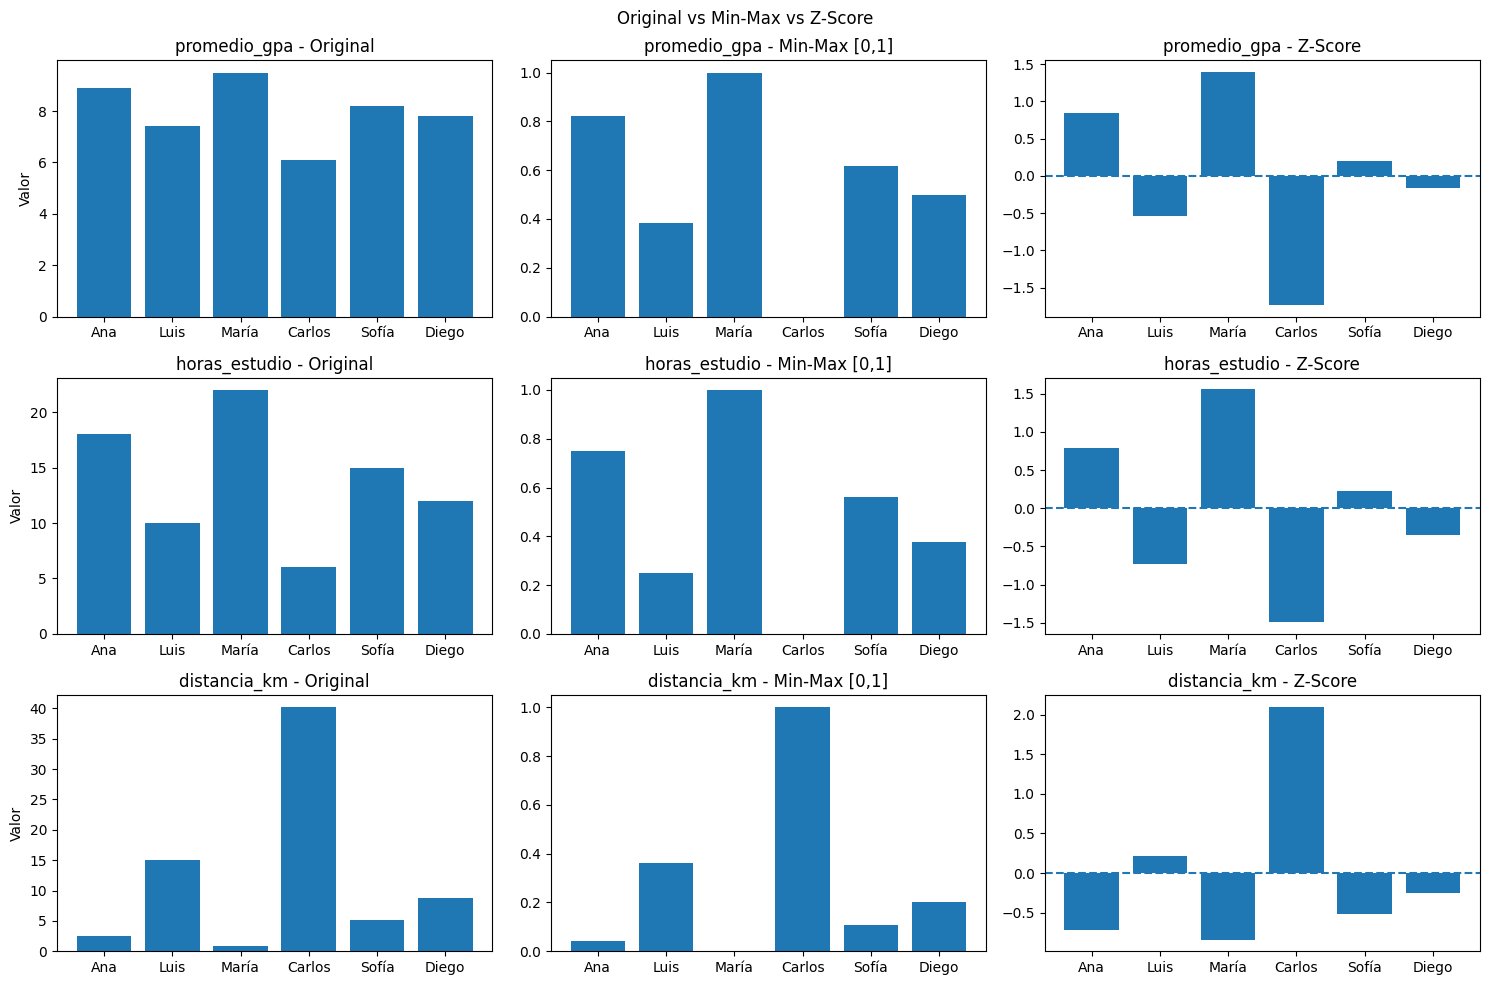

In [8]:

# ============================================
# ACTIVIDAD 2.4: COMPARACION VISUAL
# ============================================

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
nombres = df["nombre"].values

for i, col in enumerate(columnas_numericas):
    # Datos originales
    axes[i, 0].bar(nombres, X[:, i])
    axes[i, 0].set_title(f"{col} - Original")
    axes[i, 0].set_ylabel("Valor")

    # Min-Max
    axes[i, 1].bar(nombres, X_minmax[:, i])
    axes[i, 1].set_title(f"{col} - Min-Max [0,1]")

    # Z-Score
    axes[i, 2].bar(nombres, X_zscore[:, i])
    axes[i, 2].axhline(0, linestyle="--")
    axes[i, 2].set_title(f"{col} - Z-Score")

plt.suptitle("Original vs Min-Max vs Z-Score")
plt.tight_layout()
plt.savefig("comparacion_escalado.png", dpi=100)
plt.show()


In [9]:

# ============================================
# ACTIVIDAD 2.5: OUTLIER DE 120 KM
# ============================================

# Agregar un estudiante con valores extremos
X_con_outlier = np.vstack([X, [8.5, 14, 120.0]])

# Aplicar las transformaciones a los nuevos datos
X_mm_con_outlier, _, _ = min_max_manual(X_con_outlier)
X_z_con_outlier, _, _ = zscore_manual(X_con_outlier)

nombres_ext = list(nombres) + ["Nuevo"]

print("=== COMPARACION DE DISTANCIA CON OUTLIER ===")
print(f"{'Estudiante':<12} {'Original':>10} {'Min-Max':>10} {'Z-Score':>10}")
print("-" * 46)

for j, nombre in enumerate(nombres_ext):
    print(
        f"{nombre:<12} "
        f"{X_con_outlier[j, 2]:>10.1f} "
        f"{X_mm_con_outlier[j, 2]:>10.4f} "
        f"{X_z_con_outlier[j, 2]:>10.4f}"
    )


=== COMPARACION DE DISTANCIA CON OUTLIER ===
Estudiante     Original    Min-Max    Z-Score
----------------------------------------------
Ana                 2.5     0.0143    -0.6280
Luis               15.0     0.1191    -0.3137
María               0.8     0.0000    -0.6708
Carlos             40.2     0.3305     0.3201
Sofía               5.1     0.0361    -0.5626
Diego               8.7     0.0663    -0.4721
Nuevo             120.0     1.0000     2.3271


P14. ¿Se mantienen las proporciones entre estudiantes?

Sí, las transformaciones Min-Max y Z-Score son transformaciones lineales por columna, por lo que conservan el orden y las relaciones lineales entre los valores de cada variable. Lo que cambia es la escala y el punto de referencia: Min-Max utiliza el rango entre el mínimo y el máximo, mientras que Z-Score utiliza la media y la desviación estándar.

P15. ¿Qué problema genera el outlier de 120 km?

El valor extremo amplía el rango y hace que los valores Min-Max de los demás estudiantes queden más cerca de cero. Z-Score también se ve afectado porque la media y la desviación estándar cambian. Por eso, Z-Score no es realmente robusto frente a outliers. Una alternativa más resistente es RobustScaler, que utiliza la mediana y el rango intercuartílico (IQR).

In [10]:

# ============================================
# FASE 3: DATASET PALMER PENGUINS
# ============================================

url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"

df_penguins = pd.read_csv(url)

print("=== PRIMERAS 8 FILAS ===")
print(df_penguins.head(8))

print("\nDimensiones originales:", df_penguins.shape)
print("\nColumnas:", list(df_penguins.columns))

print("\n=== TIPOS DE DATOS ===")
print(df_penguins.dtypes)

print("\n=== VALORES NULOS ===")
print(df_penguins.isnull().sum())

print("\n=== ESTADISTICAS DESCRIPTIVAS ===")
print(df_penguins.describe())

print("\n=== VALORES UNICOS CATEGORICOS ===")
for col in df_penguins.select_dtypes(include="object").columns:
    print(f"{col}: {df_penguins[col].unique()}")


=== PRIMERAS 8 FILAS ===
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   
5  Adelie  Torgersen            39.3           20.6              190.0   
6  Adelie  Torgersen            38.9           17.8              181.0   
7  Adelie  Torgersen            39.2           19.6              195.0   

   body_mass_g     sex  year  
0       3750.0    male  2007  
1       3800.0  female  2007  
2       3250.0  female  2007  
3          NaN     NaN  2007  
4       3450.0  female  2007  
5       3650.0    male  2007  
6       3625.0  female  2007  
7       4675.0    male  2007  

Dimensiones originales: (344

Actividad 3.1 y 3.2: exploración y clasificación

P16. ¿Cuántas instancias tiene el dataset y cuáles son sus features numéricas?

El dataset original tiene 344 instancias. Las features numéricas utilizadas en la práctica son `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm` y `body_mass_g`. Para una tarea de clasificación, el label más lógico es `species`, porque permite predecir la especie del pingüino a partir de sus características.

P17. ¿Hay valores nulos y por qué deben tratarse?

Sí, el dataset contiene valores nulos en algunas columnas. La ubicación y cantidad exactas se comprueban con `df_penguins.isnull().sum()`. Es importante tratarlos porque muchos escaladores no aceptan valores faltantes para calcular correctamente sus parámetros. Si existen NaN, los resultados pueden quedar contaminados o producir errores según la operación utilizada.

P18. Clasificación de las variables.

Las variables numéricas `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm` y `body_mass_g` son cuantitativas continuas. `species`, `island` y `sex` son cualitativas nominales: sus categorías no tienen un orden natural. `year` es una variable cuantitativa discreta si representa el año de observación como número entero.

Sexo e isla siguen siendo nominales aunque se ordenen las islas por temperatura promedio. Ese orden solo sería relevante si se construyera una variable nueva que representara explícitamente dicha temperatura; no convierte automáticamente a la isla en una variable ordinal.

In [11]:

# ============================================
# ACTIVIDAD 3.3: LIMPIEZA Y SELECCION
# ============================================

# Eliminar las filas que tengan al menos un valor nulo
df_clean = df_penguins.dropna().copy()

print("Filas originales:", len(df_penguins))
print("Filas limpias:", len(df_clean))
print("Filas eliminadas:", len(df_penguins) - len(df_clean))

# Seleccionar las cuatro features numéricas de la guía
features_num = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

X_penguins = df_clean[features_num].values.astype(float)

print("\n=== ESTADISTICAS ANTES DEL ESCALADO ===")
print(
    pd.DataFrame(X_penguins, columns=features_num)
    .describe()
    .round(2)
)


Filas originales: 344
Filas limpias: 333
Filas eliminadas: 11

=== ESTADISTICAS ANTES DEL ESCALADO ===
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          333.00         333.00             333.00       333.00
mean            43.99          17.16             200.97      4207.06
std              5.47           1.97              14.02       805.22
min             32.10          13.10             172.00      2700.00
25%             39.50          15.60             190.00      3550.00
50%             44.50          17.30             197.00      4050.00
75%             48.60          18.70             213.00      4775.00
max             59.60          21.50             231.00      6300.00


P19. ¿Qué variable tendría más peso en el cálculo de distancia si no escalamos?

`body_mass_g` presenta valores numéricos mucho mayores que `bill_depth_mm`. En un algoritmo basado en distancias, como KNN, la masa corporal podría dominar la distancia calculada debido a su escala. Eso no significa que sea biológicamente más importante, sino que sus unidades numéricas son mayores. El escalado permite que las variables participen en una escala comparable.

In [12]:

# ============================================
# ACTIVIDAD 3.4: ESCALADO CON SKLEARN
# ============================================

# Aplicar Min-Max
mm = MinMaxScaler()
X_mm = mm.fit_transform(X_penguins)

# Aplicar Z-Score
zs = StandardScaler()
X_zs = zs.fit_transform(X_penguins)

df_mm_penguins = pd.DataFrame(X_mm, columns=features_num)
df_zs_penguins = pd.DataFrame(X_zs, columns=features_num)

print("=== ESTADISTICAS MIN-MAX ===")
print(df_mm_penguins.describe().round(4))

print("\n=== ESTADISTICAS Z-SCORE ===")
print(df_zs_penguins.describe().round(4))


=== ESTADISTICAS MIN-MAX ===
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count        333.0000       333.0000           333.0000     333.0000
mean           0.4325         0.4839             0.4910       0.4186
std            0.1989         0.2344             0.2376       0.2237
min            0.0000         0.0000             0.0000       0.0000
25%            0.2691         0.2976             0.3051       0.2361
50%            0.4509         0.5000             0.4237       0.3750
75%            0.6000         0.6667             0.6949       0.5764
max            1.0000         1.0000             1.0000       1.0000

=== ESTADISTICAS Z-SCORE ===
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count        333.0000       333.0000           333.0000     333.0000
mean          -0.0000        -0.0000             0.0000      -0.0000
std            1.0015         1.0015             1.0015       1.0015
min           -2.1780        -2.0673        

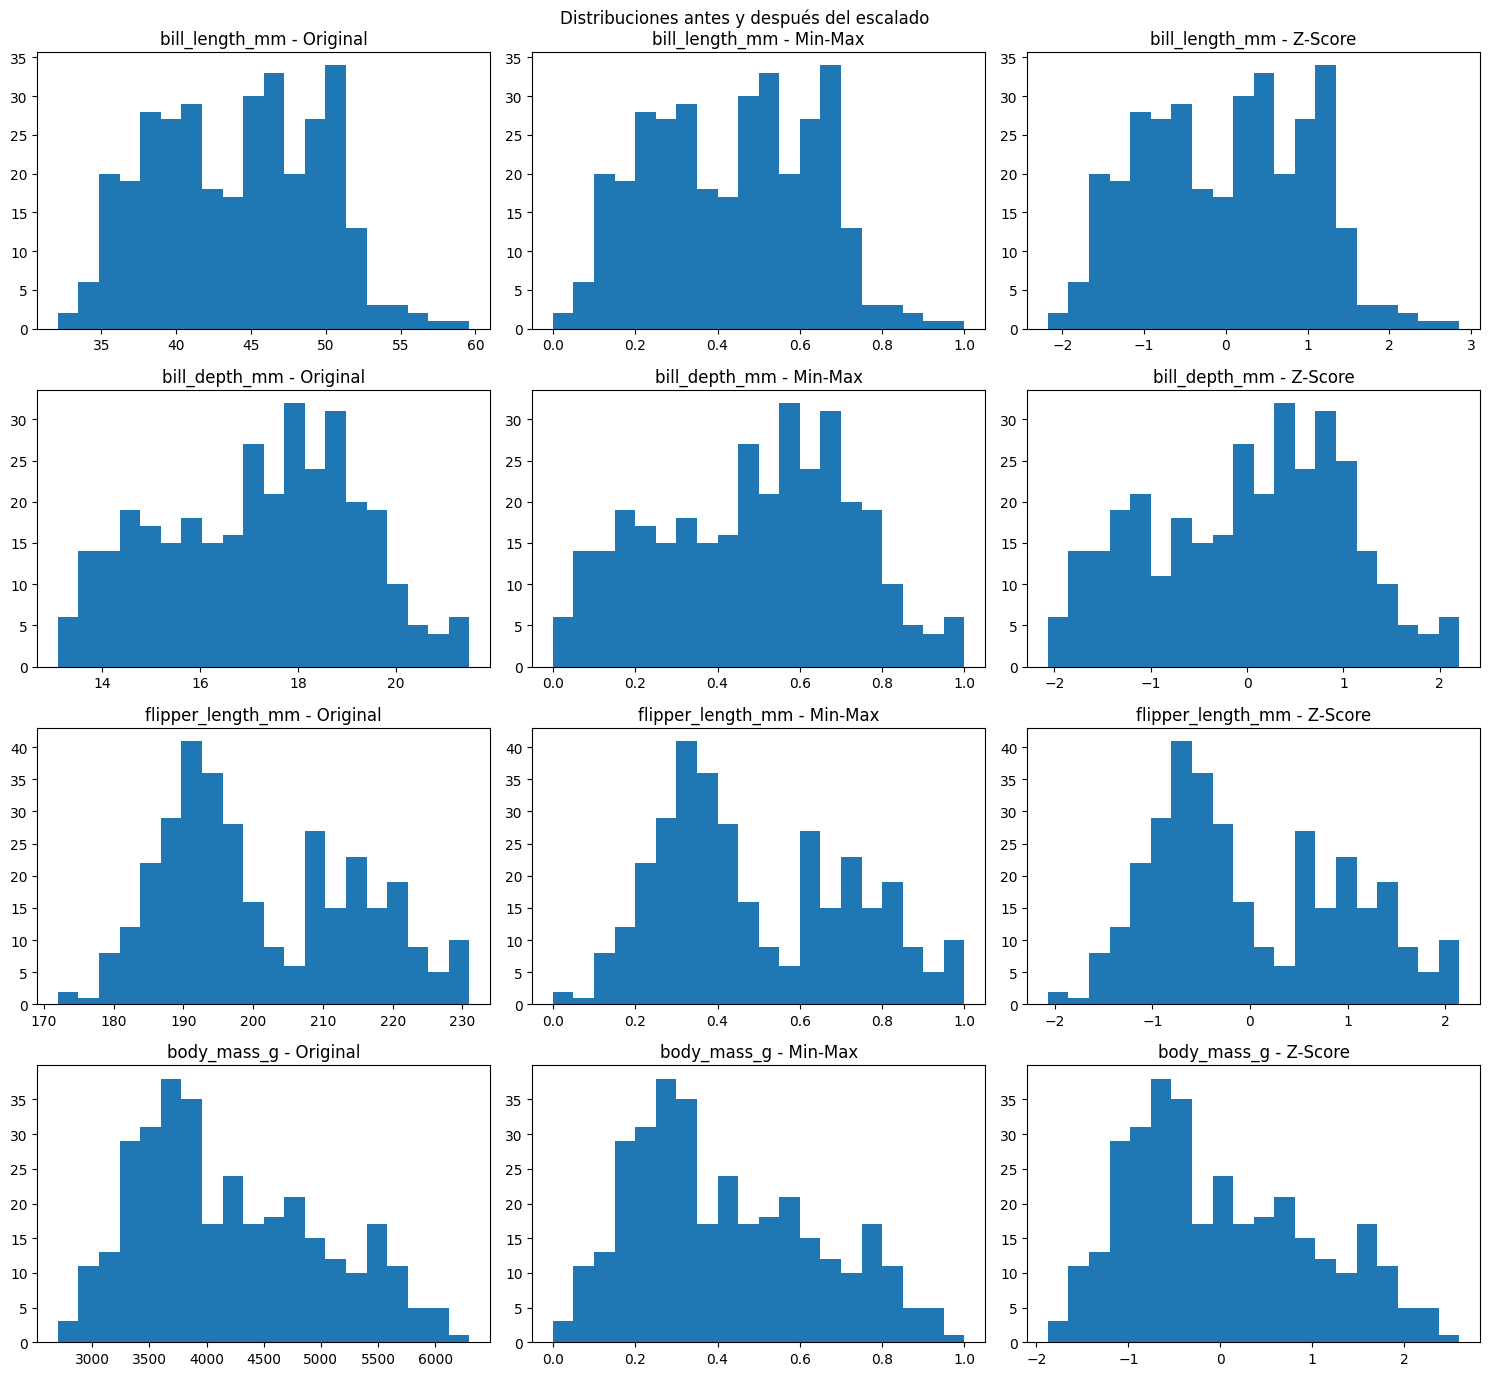

In [13]:

# ============================================
# GRAFICAS DE DISTRIBUCION
# ============================================

fig, axes = plt.subplots(4, 3, figsize=(15, 14))

for i, col in enumerate(features_num):
    # Original
    axes[i, 0].hist(df_clean[col], bins=20)
    axes[i, 0].set_title(f"{col} - Original")

    # Min-Max
    axes[i, 1].hist(df_mm_penguins[col], bins=20)
    axes[i, 1].set_title(f"{col} - Min-Max")

    # Z-Score
    axes[i, 2].hist(df_zs_penguins[col], bins=20)
    axes[i, 2].set_title(f"{col} - Z-Score")

plt.suptitle("Distribuciones antes y después del escalado")
plt.tight_layout()
plt.show()


P20. ¿El escalado cambia la forma de la distribución?

Min-Max y Z-Score son transformaciones lineales, por lo que no cambian la forma relativa de la distribución ni su asimetría. Cambian la escala y la ubicación de los valores en el eje horizontal. Por ello, el escalado por sí solo no convierte una distribución asimétrica en normal.

P21. ¿body_mass_g se parece a una campana de Gauss?

La distribución debe evaluarse observando el histograma generado. En Palmer Penguins, la masa corporal puede mostrar varios grupos o picos asociados con las diferentes especies, por lo que no necesariamente forma una única campana normal. Min-Max y Z-Score no eliminan esa estructura ni corrigen la asimetría; la presencia de valores extremos puede hacer conveniente evaluar RobustScaler.

In [14]:

# ============================================
# FASE 4: HUGGING FACE + SKLEARN
# ============================================

# Preparar nuevamente el dataset limpio
X = df_clean[features_num].values.astype(float)

print(f"Dataset listo: {X.shape[0]} instancias, {X.shape[1]} features")

print("\n=== ESTADISTICAS ORIGINALES ===")
print(
    pd.DataFrame(X, columns=features_num)
    .describe()
    .round(2)
)

# Actividad 4.1: calcular el rango de cada feature
rangos = X.max(axis=0) - X.min(axis=0)

print("\n=== RANGOS DE LAS FEATURES ===")

for col, rango in zip(features_num, rangos):
    print(f"{col}: {rango:.2f}")

print("\nFeature con mayor rango:",
      features_num[np.argmax(rangos)])

print("Feature con menor rango:",
      features_num[np.argmin(rangos)])


Dataset listo: 333 instancias, 4 features

=== ESTADISTICAS ORIGINALES ===
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          333.00         333.00             333.00       333.00
mean            43.99          17.16             200.97      4207.06
std              5.47           1.97              14.02       805.22
min             32.10          13.10             172.00      2700.00
25%             39.50          15.60             190.00      3550.00
50%             44.50          17.30             197.00      4050.00
75%             48.60          18.70             213.00      4775.00
max             59.60          21.50             231.00      6300.00

=== RANGOS DE LAS FEATURES ===
bill_length_mm: 27.50
bill_depth_mm: 8.40
flipper_length_mm: 59.00
body_mass_g: 3600.00

Feature con mayor rango: body_mass_g
Feature con menor rango: bill_depth_mm


In [15]:

# ============================================
# ACTIVIDAD 4.2: DIVISION TRAIN / TEST
# ============================================

X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

print("=== DIVISION DEL DATASET ===")
print(f"Train: {X_train.shape} -> {X_train.shape[0]} pingüinos")
print(f"Test:  {X_test.shape} -> {X_test.shape[0]} pingüinos")


=== DIVISION DEL DATASET ===
Train: (266, 4) -> 266 pingüinos
Test:  (67, 4) -> 67 pingüinos


P23. ¿Por qué se divide el dataset antes de escalarlo?

Se divide primero para evitar el *data leakage* o filtración de información. Si se escala todo el dataset antes de dividirlo, los mínimos, máximos, medias o desviaciones estándar podrían incorporar información de los datos de prueba. El modelo tendría indirectamente información del conjunto que debería utilizarse para evaluar su rendimiento. La solución es ajustar el escalador únicamente con `X_train` y después aplicar sus parámetros a `X_test` sin volver a ajustarlo.

In [16]:

# ============================================
# ACTIVIDAD 4.3: TRES ESCALADORES
# ============================================

# Crear los escaladores
mm_scaler = MinMaxScaler()
zs_scaler = StandardScaler()
rb_scaler = RobustScaler()

# Ajustar y transformar SOLO el entrenamiento
X_train_mm = mm_scaler.fit_transform(X_train)
X_train_zs = zs_scaler.fit_transform(X_train)
X_train_rb = rb_scaler.fit_transform(X_train)

# Transformar prueba con los parámetros ya aprendidos
X_test_mm = mm_scaler.transform(X_test)
X_test_zs = zs_scaler.transform(X_test)
X_test_rb = rb_scaler.transform(X_test)

print("=== MIN-MAX: PARAMETROS DE TRAIN ===")
print("Mínimos:", mm_scaler.data_min_.round(2))
print("Máximos:", mm_scaler.data_max_.round(2))

print("\n=== STANDARD SCALER: PARAMETROS DE TRAIN ===")
print("Medias:", zs_scaler.mean_.round(2))
print("Desviaciones:", zs_scaler.scale_.round(2))

print("\n=== ROBUST SCALER: PARAMETROS DE TRAIN ===")
print("Medianas:", rb_scaler.center_.round(2))
print("IQR:", rb_scaler.scale_.round(2))

print("\n=== FORMAS DE LOS DATOS TRANSFORMADOS ===")
print("Train Min-Max:", X_train_mm.shape)
print("Test Min-Max:", X_test_mm.shape)
print("Train Z-Score:", X_train_zs.shape)
print("Test Z-Score:", X_test_zs.shape)
print("Train Robust:", X_train_rb.shape)
print("Test Robust:", X_test_rb.shape)


=== MIN-MAX: PARAMETROS DE TRAIN ===
Mínimos: [  32.1   13.1  172.  2700. ]
Máximos: [  59.6   21.5  231.  6050. ]

=== STANDARD SCALER: PARAMETROS DE TRAIN ===
Medias: [  44.08   17.07  201.41 4232.61]
Desviaciones: [  5.41   1.97  14.24 809.57]

=== ROBUST SCALER: PARAMETROS DE TRAIN ===
Medianas: [  44.9   17.2  197.  4100. ]
IQR: [   8.9    3.2   24.  1200. ]

=== FORMAS DE LOS DATOS TRANSFORMADOS ===
Train Min-Max: (266, 4)
Test Min-Max: (67, 4)
Train Z-Score: (266, 4)
Test Z-Score: (67, 4)
Train Robust: (266, 4)
Test Robust: (67, 4)


In [17]:

# ============================================
# VERIFICACION MANUAL DE LOS PARAMETROS
# ============================================

# Verificar Min-Max manualmente sobre X_train
minimos_manuales = X_train.min(axis=0)
maximos_manuales = X_train.max(axis=0)

print("=== VERIFICACION MIN-MAX ===")
print("Mínimos manuales:", minimos_manuales.round(2))
print("Mínimos sklearn: ", mm_scaler.data_min_.round(2))

print("\nMáximos manuales:", maximos_manuales.round(2))
print("Máximos sklearn: ", mm_scaler.data_max_.round(2))

print("\n¿Coinciden los mínimos?",
      np.allclose(minimos_manuales, mm_scaler.data_min_))

print("¿Coinciden los máximos?",
      np.allclose(maximos_manuales, mm_scaler.data_max_))

# Verificar mediana e IQR de body_mass_g
indice_masa = features_num.index("body_mass_g")
masa_train = X_train[:, indice_masa]

mediana_manual = np.median(masa_train)
q1 = np.percentile(masa_train, 25)
q3 = np.percentile(masa_train, 75)
iqr_manual = q3 - q1

print("\n=== VERIFICACION ROBUST SCALER ===")
print(f"Mediana manual: {mediana_manual:.2f}")
print(f"Mediana sklearn: {rb_scaler.center_[indice_masa]:.2f}")

print(f"\nIQR manual: {iqr_manual:.2f}")
print(f"IQR sklearn: {rb_scaler.scale_[indice_masa]:.2f}")

print("\n¿Coinciden la mediana y el IQR?",
      np.isclose(mediana_manual, rb_scaler.center_[indice_masa])
      and np.isclose(iqr_manual, rb_scaler.scale_[indice_masa]))


=== VERIFICACION MIN-MAX ===
Mínimos manuales: [  32.1   13.1  172.  2700. ]
Mínimos sklearn:  [  32.1   13.1  172.  2700. ]

Máximos manuales: [  59.6   21.5  231.  6050. ]
Máximos sklearn:  [  59.6   21.5  231.  6050. ]

¿Coinciden los mínimos? True
¿Coinciden los máximos? True

=== VERIFICACION ROBUST SCALER ===
Mediana manual: 4100.00
Mediana sklearn: 4100.00

IQR manual: 1200.00
IQR sklearn: 1200.00

¿Coinciden la mediana y el IQR? True


Actividad 4.1 y 4.3: análisis de parámetros

P22. ¿Qué feature tiene el mayor y el menor rango?

El código calcula el rango como máximo menos mínimo para cada feature del dataset Palmer Penguins limpio. La salida identifica la variable con el mayor rango y la que tiene el menor. El rango depende de las unidades originales, por lo que no representa directamente la importancia de cada variable.

P22 de la fase final. ¿Coinciden los parámetros de MinMaxScaler con los cálculos manuales?

Sí. Cuando los cálculos se realizan sobre el mismo conjunto de entrenamiento, los mínimos y máximos manuales deben coincidir con los de `MinMaxScaler`. Las diferencias pequeñas que pudieran aparecer al mostrar los valores suelen deberse al redondeo. Es importante no comparar directamente el dataset de estudiantes de la fase 2 con Palmer Penguins, porque son conjuntos distintos.

P23 de la fase final. ¿Coinciden la mediana y el IQR de body_mass_g?

La mediana y el rango intercuartílico calculados manualmente deben coincidir con `rb_scaler.center_[3]` y `rb_scaler.scale_[3]`, respectivamente, porque ambos cálculos utilizan los mismos datos de entrenamiento y el mismo criterio de percentiles.

El IQR se calcula restando el primer cuartil al tercer cuartil: IQR = Q3 − Q1. RobustScaler utiliza la mediana para centrar los datos y el IQR para escalarlos, lo que lo hace menos sensible a los valores extremos que los métodos basados en el mínimo y máximo o en la media y desviación estándar.

# Conclusiones

1. La práctica permitió identificar las instancias, los atributos, las features y el label de un dataset, diferenciando los tipos de variables según su significado y no solamente según el tipo de dato detectado por Pandas.

2. Min-Max transforma los valores al rango de 0 a 1, mientras que Z-Score los expresa en relación con la media y la desviación estándar. Ambos métodos cambian la escala, pero no eliminan la asimetría ni los efectos de los valores extremos.

3. El análisis de Palmer Penguins permitió comprobar la importancia de revisar los valores nulos, explorar las características numéricas y aplicar el preprocesamiento antes de entrenar un modelo de aprendizaje automático.

4. RobustScaler utiliza la mediana y el rango intercuartílico, por lo que suele ser una alternativa más adecuada cuando existen valores atípicos importantes.

5. Dividir los datos en entrenamiento y prueba antes de ajustar los escaladores evita el data leakage y permite evaluar el modelo de una forma más confiable.

## Recomendaciones

- Revisar los valores nulos y los posibles valores extremos antes de escalar los datos.
- Seleccionar la técnica de escalado según la distribución de las variables y el algoritmo que se utilizará.
- Ajustar los escaladores únicamente con los datos de entrenamiento y reutilizar esos parámetros para transformar los datos de prueba.
- Verificar los resultados mediante estadísticas descriptivas y representaciones gráficas.